# Task 3 – Test results: parsing performance of the 150 Daily Mirror sentences

Each hand-tagged sentence from Task 2 is tested against the model trained on the Penn Treebank in Task 1 (`model/pos_pcfg_model.pkl`). Run Task 1 and Task 2 first.

**What is measured, and why**

| Level | Metric | Question it answers |
|---|---|---|
| Tagging (HMM) | accuracy, per-tag precision / recall / F1, Cohen's κ, confusion matrix | Does the PTB-trained tagger agree with the human tags? (Human tags are the reference.) |
| Tag pattern (HMM) | log P(t₁…tₙ) per transition, **tag-sequence perplexity** | How typical is this sentence's sequence of word categories compared with WSJ English? |
| Words + tags (HMM) | log P(w, t) per token for the human tagging; **gap** to the best (Viterbi) tagging | How likely is the sentence *with the tags the human gave it*? A large gap means the model would prefer a different analysis. |
| Words (HMM, forward algorithm) | **word perplexity** = exp(−log P(w₁…wₙ)/n) | How surprising is the text itself (vocabulary and style)? |
| Structure (PCFG) | **full-parse coverage**, **number of fragments**; log P(best parse) per token; **PCFG perplexity** | Can the treebank grammar build one tree over the tag sequence (or only pieces), and how probable is the analysis? |
| Structure robustness | labelled bracket F1 between the parse of the model's tags and the parse of the human tags | How much do tagging disagreements change the syntactic analysis? |

Scores are normalised by sentence length, because raw log-probabilities fall with every extra word and would otherwise simply rank sentences by length.

In [1]:
import os, re, math, pickle, collections, warnings
os.environ.setdefault("OMP_NUM_THREADS", "1")   # avoids a Windows-only KMeans memory-leak warning
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from nltk.tree import Tree
from sklearn.metrics import classification_report, confusion_matrix, cohen_kappa_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

INPUT = "task2_150_tagged_sentences.csv"
os.makedirs("results", exist_ok=True)
with open("model/pos_pcfg_model.pkl", "rb") as f:
    M = pickle.load(f)
hmm, BIN, LEX, ROOT = M["hmm"], M["BIN"], M["LEX"], M["ROOT"]
print(M["info"]); print("Model validation:", {k: (round(v, 4) if isinstance(v, float) else {a: round(b, 4) for a, b in v.items()}) for k, v in M["validation"].items()})

Bigram HMM (add-0.1 transitions, hapax signature unknown-word model) + tag-level PCFG (CNF, h=1) from NLTK PTB WSJ sample
Model validation: {'tagging_accuracy': 0.9473, 'parseval': {'sentences': 305, 'coverage': 0.9836, 'labelled_precision': 0.7712, 'labelled_recall': 0.734, 'labelled_F1': 0.7522}}


## 1. Model functions (identical to Task 1)

In [2]:
SUFFIXES = ["tion","sion","ment","ness","able","ible","ing","ity","ous","ful","ive","est","ers","ies","ed","ly","al","er","ic","s"]

def word_signature(w):
    sig = "UNK"
    if any(c.isdigit() for c in w): sig += "-NUM"
    if w[:1].isupper(): sig += "-CAP"
    if "-" in w: sig += "-HYPH"
    lw = w.lower()
    for suf in SUFFIXES:
        if lw.endswith(suf) and len(lw) > len(suf) + 1:
            sig += "-" + suf; break
    return sig

def train_hmm(sents, k=0.1, unk_alpha=0.1):
    tag_c, word_c = collections.Counter(), collections.Counter()
    wt_c = collections.defaultdict(collections.Counter)      # word -> tag -> count
    bigram_c = collections.defaultdict(collections.Counter)  # prev -> tag -> count
    for s in sents:
        prev = "<s>"
        for w, t in s:
            tag_c[t] += 1; word_c[w] += 1; wt_c[w][t] += 1
            bigram_c[prev][t] += 1; prev = t
        bigram_c[prev]["</s>"] += 1
    tags = sorted(tag_c)
    # transitions
    from_states, to_states = ["<s>"] + tags, tags + ["</s>"]
    trans = {}
    for p in from_states:
        tot = sum(bigram_c[p].values())
        trans[p] = {t: (bigram_c[p][t] + k) / (tot + k * len(to_states)) for t in to_states}
    # unknown-word model from hapax words
    hap = collections.defaultdict(collections.Counter)
    for w, c in word_c.items():
        if c == 1:
            for t, n in wt_c[w].items(): hap[t][word_signature(w)] += n
    sigs = sorted({s for t in hap for s in hap[t]} | {"UNK"})
    # P(unseen word with signature s | t) = P(unseen | t) * P(s | unseen, t)
    #   P(unseen | t): share of tag t's tokens that are hapax words -> close to 0 for closed classes (DT, IN, UH...)
    #   P(s | unseen, t): hapax signature counts, smoothed towards the overall signature distribution
    hap_tot = collections.Counter({s: sum(hap[t][s] for t in hap) for s in sigs})
    H = sum(hap_tot.values())
    p_sig = {s: (hap_tot[s] + unk_alpha) / (H + unk_alpha * len(sigs)) for s in sigs}
    unk = {}
    for t in tags:
        ht = sum(hap[t].values())
        p_unseen = (ht + 0.01) / (tag_c[t] + 1)
        unk[t] = {s: p_unseen * (hap[t][s] + p_sig[s]) / (ht + 1) for s in sigs}
    return dict(tags=tags, tag_counts=dict(tag_c), word_counts=dict(word_c),
                wt_counts={w: dict(c) for w, c in wt_c.items()},
                bigram_counts={p: dict(c) for p, c in bigram_c.items()},
                trans=trans, unk=unk, signatures=sigs, k=k)

def lookup(hmm, w):
    if w in hmm["wt_counts"]: return w
    if w.lower() in hmm["wt_counts"]: return w.lower()
    return None

def emit_prob(hmm, w, t):
    s = word_signature(w)
    pu = hmm["unk"][t].get(s, hmm["unk"][t]["UNK"])
    key = lookup(hmm, w)
    if key is None:
        return pu
    # known word: add-epsilon smoothing over the vocabulary, so a tag never seen with this word
    # is possible but strongly penalised (rare tags such as FW/UH no longer attract common words)
    eps = 0.001
    return (hmm["wt_counts"][key].get(t, 0) + eps) / (hmm["tag_counts"][t] + eps * len(hmm["word_counts"]))

def viterbi(hmm, words):
    tags, T = hmm["tags"], hmm["trans"]
    lt = {p: {t: math.log(v) for t, v in T[p].items()} for p in T}
    V = [{t: lt["<s>"][t] + math.log(emit_prob(hmm, words[0], t)) for t in tags}]
    back = [{}]
    for i in range(1, len(words)):
        V.append({}); back.append({})
        em = {t: math.log(emit_prob(hmm, words[i], t)) for t in tags}
        for t in tags:
            best_p, best = max(((V[i-1][p] + lt[p][t], p) for p in tags))
            V[i][t] = best_p + em[t]; back[i][t] = best
    best_score, last = max((V[-1][t] + lt[t]["</s>"], t) for t in tags)
    path = [last]
    for i in range(len(words) - 1, 0, -1):
        path.append(back[i][path[-1]])
    return path[::-1], best_score

def joint_logprob(hmm, words, tags):
    # log P(words, tags): how likely this exact tagging is under the model
    lp, prev = 0.0, "<s>"
    for w, t in zip(words, tags):
        if t not in hmm["trans"][prev]:   # tag unknown to the model
            return float("-inf")
        lp += math.log(hmm["trans"][prev][t]) + math.log(emit_prob(hmm, w, t)); prev = t
    return lp + math.log(hmm["trans"][prev]["</s>"])

In [3]:
def cky_chart(tags, BIN, LEX, beam=40):
    n = len(tags)
    chart = [[None] * (n + 1) for _ in range(n + 1)]
    for i, t in enumerate(tags):
        chart[i][i + 1] = {A: (lp, t) for A, lp in LEX.get(t, [])}
    for span in range(2, n + 1):
        for i in range(0, n - span + 1):
            j = i + span; cell = {}
            for k in range(i + 1, j):
                L, R = chart[i][k], chart[k][j]
                if not L or not R: continue
                for B, (lb, _) in L.items():
                    for C, (lc, _) in R.items():
                        rules = BIN.get((B, C))
                        if not rules: continue
                        base = lb + lc
                        for A, lp in rules:
                            s = base + lp
                            if A not in cell or s > cell[A][0]:
                                cell[A] = (s, (k, B, C))
            if len(cell) > beam:
                cell = dict(sorted(cell.items(), key=lambda x: -x[1][0])[:beam])
            chart[i][j] = cell
    return chart

def build_tree(chart, i, j, A):
    bp = chart[i][j][A][1]
    if isinstance(bp, str):
        return Tree(A, [bp])
    k, B, C = bp
    return Tree(A, [build_tree(chart, i, k, B), build_tree(chart, k, j, C)])

def cky_parse(tags, BIN, LEX, ROOT, beam=40):
    # most probable full parse: returns (tree, log P) or (None, -inf) if the grammar cannot span the sentence
    n = len(tags); chart = cky_chart(tags, BIN, LEX, beam)
    top = chart[0][n] or {}
    cands = [(top[X][0] + lp, X) for X, lp in ROOT.items() if X in top]
    if not cands:
        return None, float("-inf")
    best, X = max(cands)
    return Tree("TOP", [build_tree(chart, 0, n, X)]), best

def cky_parse_robust(tags, BIN, LEX, ROOT, beam=40):
    # Full parse if possible; otherwise the fewest, most probable constituents that cover the sentence
    # (a fragment parse). Returns (tree, log P, number_of_fragments); 1 fragment = full parse.
    n = len(tags); chart = cky_chart(tags, BIN, LEX, beam)
    top = chart[0][n] or {}
    cands = [(top[X][0] + lp, X) for X, lp in ROOT.items() if X in top]
    if cands:
        best, X = max(cands)
        return Tree("TOP", [build_tree(chart, 0, n, X)]), best, 1
    # DP over split points: minimise #fragments, then maximise log-probability
    best = [(0, 0.0, None)] + [(10**9, float("-inf"), None)] * n
    for j in range(1, n + 1):
        for i in range(j):
            if best[i][0] >= 10**9 or not chart[i][j]: continue
            A, (lp, _) = max(chart[i][j].items(), key=lambda x: x[1][0])
            cand = (best[i][0] + 1, best[i][1] + lp, (i, A))
            if (cand[0], -cand[1]) < (best[j][0], -best[j][1]):
                best[j] = cand
    frags, j = [], n
    while j > 0:
        i, A = best[j][2]; frags.append(build_tree(chart, i, j, A)); j = i
    # each extra fragment is charged the log-probability of the rarest binary rule in the grammar,
    # so a fragment parse can never look more probable than a full parse of the same length
    penalty = min(lp for rules in BIN.values() for _, lp in rules)
    return Tree("TOP", [Tree("FRAG", frags[::-1])]), best[n][1] + (best[n][0] - 1) * penalty, best[n][0]

def debinarise(t):
    # Undo the CNF transform: splice out artificial "X|<...>" nodes and expand collapsed unary chains "A+B".
    # (Written by hand instead of nltk's un_chomsky_normal_form, whose behaviour differs between NLTK versions.)
    def rec(node):
        if isinstance(node, str):
            return [node]
        kids = [k for c in node for k in rec(c)]
        lab = node.label()
        if "|<" in lab:
            return kids
        parts = lab.split("+")
        tree = Tree(parts[-1], kids)
        for p in reversed(parts[:-1]):
            tree = Tree(p, [tree])
        return [tree]
    out = rec(t)
    return out[0] if len(out) == 1 else Tree("TOP", out)


def brackets(t):
    out = collections.Counter()
    def walk(node, start):
        if isinstance(node, str): return start + 1
        if node.height() == 2: return start + 1   # preterminal
        end = start
        for c in node: end = walk(c, end)
        if node.label() != "TOP": out[(node.label(), start, end)] += 1
        return end
    walk(t, 0); return out


def forward_logprob(hmm, words):
    # log P(w_1..n), summing over all tag sequences (forward algorithm, log space)
    tags, T = hmm["tags"], hmm["trans"]
    def lse(xs):
        m = max(xs); return m + math.log(sum(math.exp(x - m) for x in xs))
    a = {t: math.log(T["<s>"][t]) + math.log(emit_prob(hmm, words[0], t)) for t in tags}
    for w in words[1:]:
        em = {t: math.log(emit_prob(hmm, w, t)) for t in tags}
        a = {t: lse([a[p] + math.log(T[p][t]) for p in tags]) + em[t] for t in tags}
    return lse([a[t] + math.log(T[t]["</s>"]) for t in tags])

def tagseq_logprob(hmm, tags):
    lp, prev = 0.0, "<s>"
    for t in tags + ["</s>"]:
        lp += math.log(hmm["trans"][prev][t]); prev = t
    return lp

## 2. Load the 150 hand-tagged sentences

In [4]:
df = pd.read_csv(INPUT, dtype=str, keep_default_na=False)
df["sent_id"] = df.sent_id.astype(int); df["token_id"] = df.token_id.astype(int)
if "tag_ptb" in df: df["tag"] = df.tag_ptb       # course-sheet tags already mapped to original PTB spelling in Task 2
sents = [(sid, g.token.tolist(), g.tag.str.strip().tolist()) for sid, g in df.sort_values(["sent_id", "token_id"]).groupby("sent_id")]
bad = sorted(set(df.tag) - set(hmm["tags"]))
assert not bad, f"Tags not in the PTB model: {bad}. Fix them in Task 2."
print(len(sents), "sentences,", len(df), "tokens")

150 sentences, 4237 tokens


## 3. Score every sentence

In [5]:
rows, all_gold, all_pred, all_oov = [], [], [], []
for sid, words, gold in sents:
    n = len(words)
    pred, best_lp = viterbi(hmm, words)
    gold_lp = joint_logprob(hmm, words, gold)
    oov = [lookup(hmm, w) is None for w in words]
    fwd = forward_logprob(hmm, words)
    ts_lp = tagseq_logprob(hmm, gold)
    tree_g, pl_g, frag_g = cky_parse_robust(gold, BIN, LEX, ROOT)
    tree_p, pl_p, frag_p = cky_parse_robust(pred, BIN, LEX, ROOT)
    if True:
        bg, bp = brackets(debinarise(tree_g)), brackets(debinarise(tree_p))
        m = sum((bg & bp).values()); P_, R_ = m / max(1, sum(bp.values())), m / max(1, sum(bg.values()))
        struct_f1 = 2 * P_ * R_ / (P_ + R_) if P_ + R_ else 0.0
        rows.append(dict(
        sent_id=sid, n_tokens=n, sentence=" ".join(words),
        tag_accuracy=np.mean([g == p for g, p in zip(gold, pred)]),
        n_tag_errors=sum(g != p for g, p in zip(gold, pred)),
        oov_rate=np.mean(oov),
        hmm_logp_gold_per_tok=gold_lp / (n + 1),
        hmm_logp_best_per_tok=best_lp / (n + 1),
        tagging_gap_per_tok=(best_lp - gold_lp) / (n + 1),
        tagseq_perplexity=math.exp(-ts_lp / (n + 1)),
        word_perplexity=math.exp(-fwd / n),
        pcfg_parsed=frag_g == 1,
        pcfg_fragments=frag_g,
        pcfg_logp_per_tok=pl_g / n,
        pcfg_perplexity=math.exp(-pl_g / n),
        structure_f1_model_vs_human=struct_f1,
        gold_tags=" ".join(gold), model_tags=" ".join(pred),
        best_parse=" ".join(str(debinarise(tree_g)).split())))
    all_gold += gold; all_pred += pred; all_oov += oov
res = pd.DataFrame(rows)
print(f"Scored {len(res)} sentences")
res.drop(columns=["sentence", "gold_tags", "model_tags", "best_parse"]).describe().T.round(3)

Scored 150 sentences


,count,mean,std,min,25%,50%,75%,max
sent_id,150.0,75.500,43.445,1.000,38.250,75.500,112.750,150.000
n_tokens,150.0,28.247,10.280,9.000,21.000,28.000,34.000,63.000
tag_accuracy,150.0,0.898,0.069,0.706,0.857,0.905,0.944,1.000
n_tag_errors,150.0,2.880,2.282,0.000,1.000,2.000,4.000,13.000
oov_rate,150.0,0.165,0.094,0.000,0.100,0.148,0.227,0.400
hmm_logp_gold_per_tok,150.0,-6.438,0.781,-8.346,-6.857,-6.478,-5.993,-4.458
hmm_logp_best_per_tok,150.0,-5.927,0.582,-7.256,-6.340,-5.964,-5.529,-4.358
tagging_gap_per_tok,150.0,0.511,0.455,-0.000,0.124,0.435,0.744,1.913
tagseq_perplexity,150.0,11.455,3.702,6.186,8.827,10.766,13.040,27.565
word_perplexity,150.0,536.533,324.485,95.819,319.930,484.075,676.122,1847.150


## 4. Tagging performance (human tags = reference)

In [6]:
G, Pp, O = np.array(all_gold), np.array(all_pred), np.array(all_oov)
tags_used = sorted(set(G) | set(Pp))
rep = pd.DataFrame(classification_report(G, Pp, labels=tags_used, output_dict=True, zero_division=0)).T
overall = pd.Series({
    "tokens": len(G), "sentences": len(res),
    "token accuracy": (G == Pp).mean(),
    "accuracy on known words": (G[~O] == Pp[~O]).mean(),
    "accuracy on unknown words": (G[O] == Pp[O]).mean() if O.any() else np.nan,
    "unknown-word rate": O.mean(),
    "macro precision": rep.loc["macro avg", "precision"], "macro recall": rep.loc["macro avg", "recall"], "macro F1": rep.loc["macro avg", "f1-score"],
    "weighted F1": rep.loc["weighted avg", "f1-score"],
    "Cohen's kappa (model vs human)": cohen_kappa_score(G, Pp),
    "sentences fully correct": (res.n_tag_errors == 0).mean(),
    "PCFG full-parse coverage": res.pcfg_parsed.mean(),
    "mean PCFG fragments": res.pcfg_fragments.mean(),
    "mean structure F1 (model tags vs human tags)": res.structure_f1_model_vs_human.mean(),
    "mean word perplexity": res.word_perplexity.mean(), "median word perplexity": res.word_perplexity.median(),
    "mean tag-sequence perplexity": res.tagseq_perplexity.mean(),
    "mean PCFG perplexity": res.pcfg_perplexity.mean()})
overall.to_frame("value").to_csv("results/overall_metrics.csv")
per_tag = rep.drop(index=["accuracy", "macro avg", "weighted avg"], errors="ignore").sort_values("support", ascending=False)
per_tag.to_csv("results/per_tag_metrics.csv")
display(overall.round(4).to_frame("value"))
per_tag.round(3)

,value
tokens,4237.0000
sentences,150.0000
token accuracy,0.8980
accuracy on known words,0.9168
accuracy on unknown words,0.8053
unknown-word rate,0.1685
macro precision,0.7462
macro recall,0.7518
macro F1,0.7439
weighted F1,0.8994


,precision,recall,f1-score,support
NN,0.824,0.853,0.838,578.0
IN,0.985,0.970,0.978,471.0
NNP,0.890,0.830,0.859,459.0
DT,0.994,0.967,0.980,362.0
NNS,0.945,0.939,0.942,347.0
JJ,0.683,0.820,0.745,255.0
",",1.000,1.000,1.000,254.0
VBD,0.850,0.667,0.747,153.0
.,1.000,1.000,1.000,152.0
CC,1.000,1.000,1.000,149.0


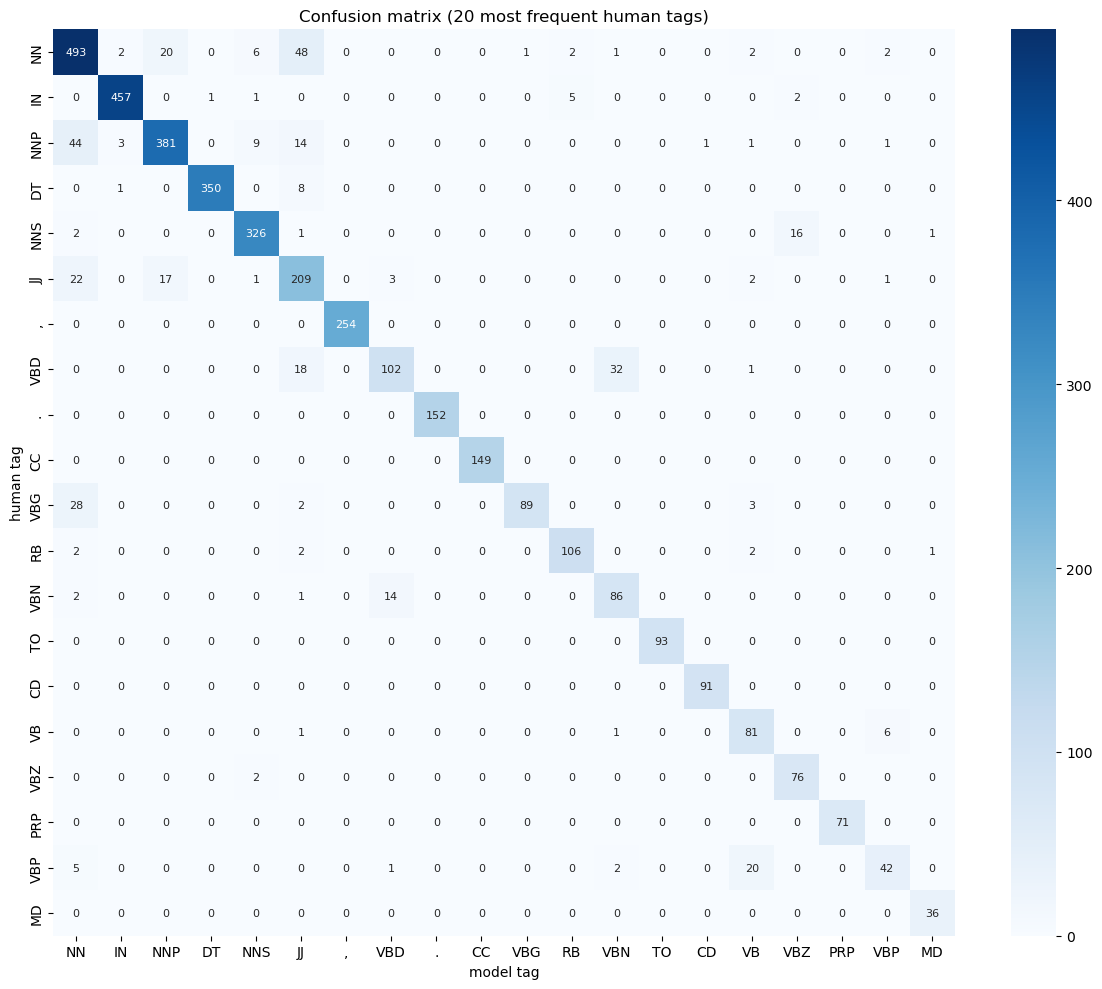

,human,model,count,example words
0,NN,JJ,48,"preschool, illicit, simple, behaviour, white"
1,NNP,NN,44,"MW, Promotion, Campus, Consultant, Programme"
2,VBD,VBN,32,"conducted, seated, connected, aimed, involved"
3,VBG,NN,28,"learning, trafficking, understanding, teaching..."
4,JJ,NN,22,"solar, official, crystal, consultant, sedentary"
5,VBP,VB,20,"learn, sleep, watch, receive, contribute"
6,NN,NNP,20,"Sadewmi, Drug, Alongside, Iran, Energy"
7,VBD,JJ,18,"integrated, ground-mounted, extended, eye-rela..."
8,JJ,NNP,17,"National, Northern, Medical, General, Western"
9,NNS,VBZ,16,"routes, girls, leaves, programmes, introduces"


In [7]:
top = pd.Series(G).value_counts().index[:20].tolist()
cm = pd.DataFrame(confusion_matrix(G, Pp, labels=top), index=top, columns=top)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", annot_kws={"size": 8})
plt.xlabel("model tag"); plt.ylabel("human tag"); plt.title("Confusion matrix (20 most frequent human tags)")
plt.tight_layout(); plt.savefig("results/confusion_matrix.png", dpi=120); plt.show()

errs = collections.Counter((g, p) for g, p in zip(G, Pp) if g != p)
err_words = collections.defaultdict(collections.Counter)
for (sid, words, gold), (_, r) in zip(sents, res.iterrows()):
    for w, g, p in zip(words, gold, r.model_tags.split()):
        if g != p: err_words[(g, p)][w] += 1
top_err = pd.DataFrame([{"human": g, "model": p, "count": c, "example words": ", ".join(w for w, _ in err_words[(g, p)].most_common(5))}
                        for (g, p), c in errs.most_common(15)])
top_err.to_csv("results/top_tag_confusions.csv", index=False); top_err

## 5. Clustering the sentences by probabilistic alignment with the PTB

**Features.** Each sentence is described by four length-normalised measures:
* `hmm_logp_gold_per_tok`: how probable the words *with their human tags* are under the HMM;
* `pcfg_logp_per_tok`: how probable the best PCFG tree over the human tags is;
* `tag_accuracy`: agreement between the model and the human tags;
* `oov_rate`: the share of words the model has never seen.

Almost every sentence gets a full PCFG parse, so the number of fragments is nearly constant. It is therefore reported for each sentence but left out of the clustering, where it would only split off one or two outliers. Its effect is still visible through `pcfg_logp_per_tok`, which includes the fragment penalty.

**Method.** The features are standardised (z-scores), then clustered with k-means. The number of clusters is chosen by silhouette score over k = 2…5. k = 3 (high / medium / low) is kept unless another k scores clearly higher, by more than 0.05. Clusters are named by their mean **alignment score**, the average of the z-scores with `oov_rate` negated, so that higher always means "more PTB-like". This value-based rationale is what the brief asks for: a cluster is "High alignment" because its sentences are both probable under the model and agree with it, not because of the topic.

In [8]:
feat_cols = ["hmm_logp_gold_per_tok", "pcfg_logp_per_tok", "tag_accuracy", "oov_rate"]
X = res[feat_cols].copy()
Z = StandardScaler().fit_transform(X)
sign = np.array([1, 1, 1, -1])
res["alignment_score"] = (Z * sign).mean(axis=1)

sil = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=0).fit_predict(Z)) for k in range(2, 6)}
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()})
# k = 3 (high / medium / low) unless another k is clearly better (> 0.05 higher silhouette)
K = 3 if sil[3] >= max(sil.values()) - 0.05 else max(sil, key=sil.get)
print("Chosen k =", K)
km = KMeans(K, n_init=20, random_state=0).fit(Z)
res["cluster_raw"] = km.labels_
order = res.groupby("cluster_raw").alignment_score.mean().sort_values(ascending=False).index
names = {3: ["High alignment", "Medium alignment", "Low alignment"], 2: ["High alignment", "Low alignment"],
         4: ["High alignment", "Medium-high alignment", "Medium-low alignment", "Low alignment"],
         5: ["Very high", "High", "Medium", "Low", "Very low"]}[K]
res["cluster"] = res.cluster_raw.map(dict(zip(order, names)))
res["cluster"] = pd.Categorical(res.cluster, categories=names, ordered=True)

profile = res.groupby("cluster", observed=True).agg(
    sentences=("sent_id", "size"), mean_tokens=("n_tokens", "mean"), tag_accuracy=("tag_accuracy", "mean"),
    oov_rate=("oov_rate", "mean"), hmm_logp_gold_per_tok=("hmm_logp_gold_per_tok", "mean"),
    word_perplexity=("word_perplexity", "median"), tagseq_perplexity=("tagseq_perplexity", "mean"),
    pcfg_logp_per_tok=("pcfg_logp_per_tok", "mean"), full_parse_rate=("pcfg_parsed", "mean"), mean_fragments=("pcfg_fragments", "mean"),
    structure_f1=("structure_f1_model_vs_human", "mean"), alignment_score=("alignment_score", "mean"))
profile.to_csv("results/cluster_profile.csv"); profile.round(3)

Silhouette by k: {2: 0.245, 3: 0.269, 4: 0.27, 5: 0.262}
Chosen k = 3


,sentences,mean_tokens,tag_accuracy,oov_rate,hmm_logp_gold_per_tok,word_perplexity,tagseq_perplexity,pcfg_logp_per_tok,full_parse_rate,mean_fragments,structure_f1,alignment_score
cluster,,,,,,,,,,,,
High alignment,38,25.447,0.932,0.246,-5.523,254.562,9.121,-2.405,1.000,1.000,0.850,0.409
Medium alignment,69,29.652,0.931,0.108,-6.479,554.651,12.607,-2.844,0.986,1.101,0.798,0.171
Low alignment,43,28.465,0.816,0.185,-7.180,620.453,11.670,-2.779,0.977,1.070,0.615,-0.636


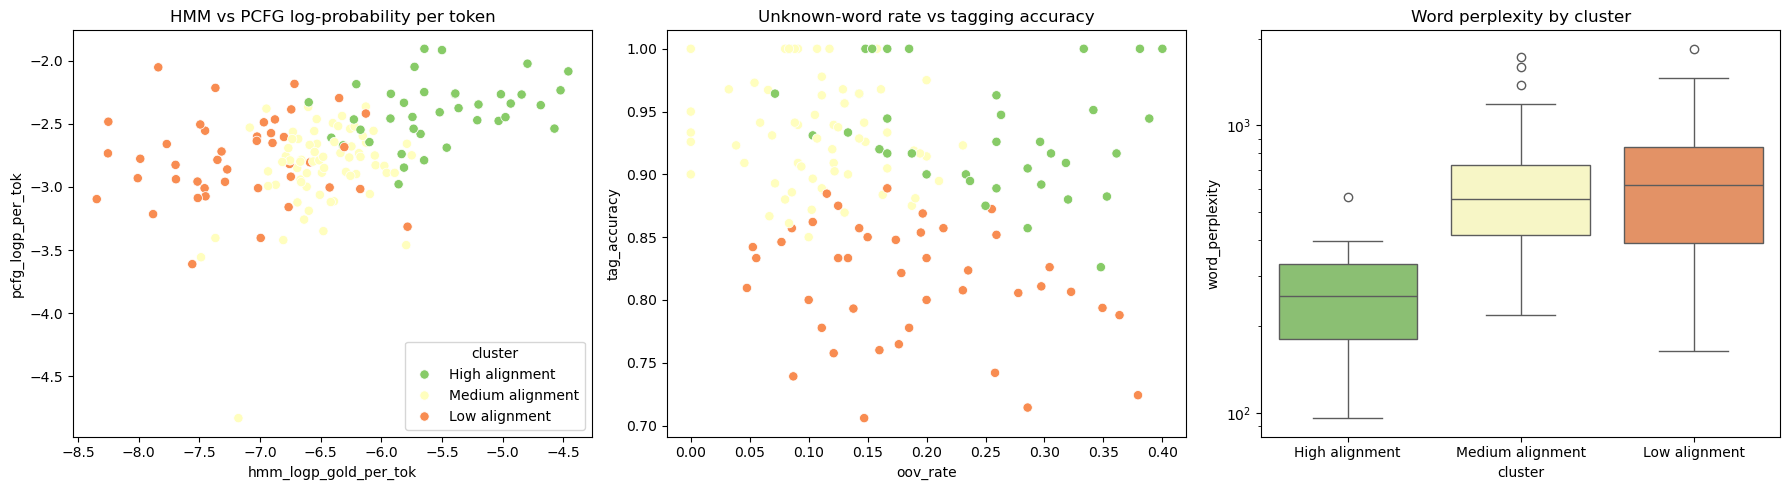

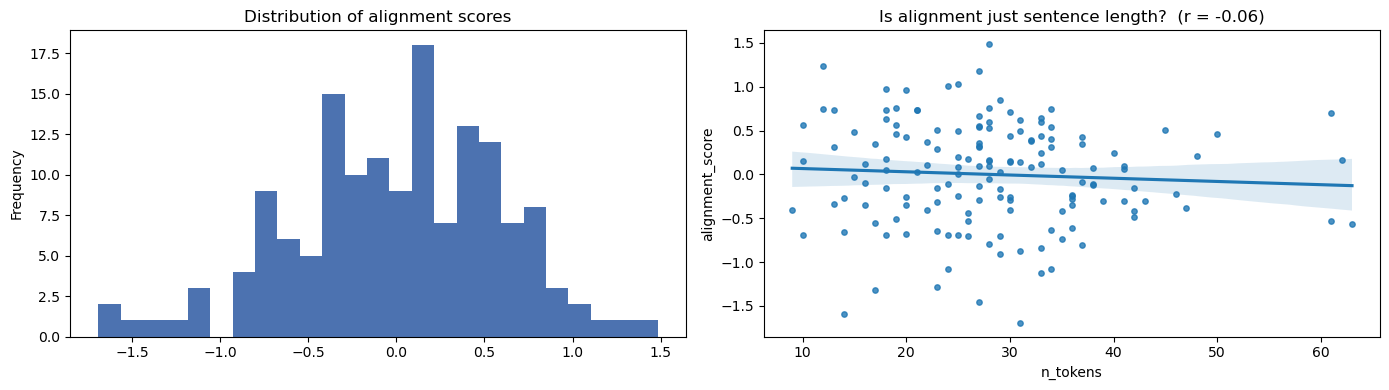

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
pal = dict(zip(names, sns.color_palette("RdYlGn_r", len(names))))
sns.scatterplot(data=res, x="hmm_logp_gold_per_tok", y="pcfg_logp_per_tok", hue="cluster", palette=pal, s=45, ax=ax[0])
ax[0].set_title("HMM vs PCFG log-probability per token")
sns.scatterplot(data=res, x="oov_rate", y="tag_accuracy", hue="cluster", palette=pal, s=45, ax=ax[1], legend=False)
ax[1].set_title("Unknown-word rate vs tagging accuracy")
sns.boxplot(data=res, x="cluster", y="word_perplexity", hue="cluster", palette=pal, ax=ax[2], legend=False)
ax[2].set_yscale("log"); ax[2].set_title("Word perplexity by cluster")
plt.tight_layout(); plt.savefig("results/clusters.png", dpi=120); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
res.alignment_score.plot.hist(bins=25, ax=ax[0], color="#4C72B0", title="Distribution of alignment scores")
sns.regplot(data=res, x="n_tokens", y="alignment_score", ax=ax[1], scatter_kws={"s": 15})
ax[1].set_title("Is alignment just sentence length?  (r = %.2f)" % res[["n_tokens", "alignment_score"]].corr().iloc[0, 1])
plt.tight_layout(); plt.savefig("results/alignment_distribution.png", dpi=120); plt.show()

### 5.1 Example sentences from each cluster (three nearest the cluster centre, plus the extreme)

In [10]:
ex_rows = []
for c in names:
    g = res[res.cluster == c]
    if g.empty: continue
    centre = g.alignment_score.median()
    picks = g.iloc[(g.alignment_score - centre).abs().argsort()[:3]]
    extreme = g.loc[[g.alignment_score.idxmax() if c == names[0] else g.alignment_score.idxmin()]]
    for kind, sub in [("typical", picks), ("extreme", extreme)]:
        for _, r in sub.iterrows():
            ex_rows.append({"cluster": c, "kind": kind, "sent_id": r.sent_id, "alignment": round(r.alignment_score, 2),
                            "tag_acc": round(r.tag_accuracy, 2), "oov": round(r.oov_rate, 2),
                            "pcfg_logp/tok": round(r.pcfg_logp_per_tok, 2), "fragments": r.pcfg_fragments, "sentence": r.sentence})
examples = pd.DataFrame(ex_rows).drop_duplicates(["cluster", "sent_id"])
examples.to_csv("results/cluster_examples.csv", index=False)
with pd.option_context("display.max_colwidth", 200):
    display(examples)

,cluster,kind,sent_id,alignment,tag_acc,oov,pcfg_logp/tok,fragments,sentence
0,High alignment,typical,33,0.50,0.92,0.16,-2.45,1,"The government plans to increase solar power capacity connected to the national grid by a further 4,585.7 MW by 2029 , the Minister said ."
1,High alignment,typical,47,0.54,0.96,0.26,-2.47,1,The verbal clash was witnessed between them when Mr Jayasekara said that there is a division within the government on the 22nd Amendment to the constitution .
2,High alignment,typical,48,0.56,0.93,0.30,-2.35,1,"`` The government was hiding the fact. Mr Rathnayake revealed the truth , saying there is fractional division within the government , '' MP Jayasekara said ."
3,High alignment,extreme,52,1.49,0.96,0.07,-2.02,1,"`` You said you did not work with divisions as a government , but there was a fractional division within the government , '' the MP said ."
4,Medium alignment,typical,7,0.16,0.89,0.11,-2.38,1,"For children between two and five years , screen time should not exceed 60 minutes a day and should preferably be limited to 30 to 45 minutes per day , according to Dr Enoka Wickramasinghe , Consu..."
5,Medium alignment,typical,101,0.16,0.93,0.11,-2.85,1,"`` If the necessary conditions are met , the strait can be reopened , a normal maritime passage restored within seven days , '' Araghchi told reporters ."
6,Medium alignment,typical,125,0.16,0.89,0.07,-2.91,1,`` Will a deal be made with Iran that lets them rebuild and create a far greater country than it ever was before ? '' he said .
7,Medium alignment,extreme,129,-1.08,1.00,0.08,-4.83,8,The Level 3 -LRB- Red -RRB- warning is effective from 4.00 p.m. today -LRB- 25 -RRB- until 4.00 p.m. tomorrow -LRB- 26 -RRB- .
8,Low alignment,typical,36,-0.61,0.81,0.28,-2.47,1,"The Sri Lanka Navy has seized illicit drugs estimated to be worth more than Rs. 55 billion through maritime and coastal anti-narcotics operations conducted so far this year , Navy Spokesman Comman..."
9,Low alignment,typical,80,-0.63,0.82,0.24,-2.82,1,"Through simple clinical scenarios , small-group discussions , models , prosected specimens , imaging , basic clinical observations and skills-lab activities , they learn to ask important questions..."


In [11]:
# Tag-level disagreements in one low-alignment sentence, word by word
low = res[res.cluster == names[-1]].sort_values("alignment_score").iloc[0]
w, g, p = low.sentence.split(), low.gold_tags.split(), low.model_tags.split()
print(f"Sentence {low.sent_id} (alignment {low.alignment_score:.2f})")
display(pd.DataFrame({"word": w, "human": g, "model": p, "match": [a == b for a, b in zip(g, p)],
                      "known word": [lookup(hmm, x) is not None for x in w]}).T)
Tree.fromstring(low.best_parse).pretty_print()

Sentence 86 (alignment -1.69)


,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
word,Assessment,includes,anatomy,practical,work,",",simple,integrated,clinical,cases,...,",",professionalism,",",teamwork,and,a,final,integrated,assessment,.
human,JJ,VBZ,NN,JJ,NN,",",NN,VBD,JJ,NNS,...,",",NN,",",NN,CC,DT,JJ,VBD,JJ,.
model,NNP,VBZ,JJ,JJ,NN,",",JJ,JJ,JJ,NNS,...,",",NN,",",NN,CC,DT,JJ,JJ,NN,.
match,False,True,False,True,True,True,False,False,True,True,...,True,True,True,True,True,True,True,False,False,True
known word,False,True,False,True,True,True,True,True,False,True,...,True,False,True,False,True,True,True,True,False,True


                                                                         TOP                                                                         
                                                                          |                                                                           
                                                                          S                                                                          
          ________________________________________________________________|________________________________________________________________________   
         S                |                                                   NP                                                          |        | 
         |                |    _______________________________________________|___                                                        |        |  
        ADJP              |   |                                                  UCP             

## 6. Save the full per-sentence test results

In [12]:
res.to_csv("results/per_sentence_results.csv", index=False)
with pd.ExcelWriter("results/Task3_test_results.xlsx") as xw:
    overall.to_frame("value").to_excel(xw, sheet_name="overall")
    res.drop(columns=["cluster_raw"]).to_excel(xw, sheet_name="per_sentence", index=False)
    per_tag.to_excel(xw, sheet_name="per_tag")
    profile.to_excel(xw, sheet_name="clusters")
    examples.to_excel(xw, sheet_name="cluster_examples", index=False)
    top_err.to_excel(xw, sheet_name="top_confusions", index=False)
for f in sorted(os.listdir("results")): print(f)

Task3_findings.md
Task3_test_results.xlsx
alignment_by_article.csv
alignment_distribution.png
cluster_examples.csv
cluster_profile.csv
clusters.png
confusion_matrix.png
overall_metrics.csv
per_sentence_results.csv
per_tag_metrics.csv
top_tag_confusions.csv


## 7. Auto-generated findings

The cell below writes `results/Task3_findings.md` from the actual numbers, as a starting point for the written report.

In [13]:
o = overall
kappa = o["Cohen's kappa (model vs human)"]
lines = [f"# Task 3 findings (auto-generated)\n",
 f"* {int(o['sentences'])} sentences, {int(o['tokens'])} tokens; {o['unknown-word rate']:.1%} of tokens are unseen in the PTB training data.",
 f"* The PTB-trained tagger agrees with the human tags on **{o['token accuracy']:.1%}** of tokens (κ = {kappa:.3f}); "
 f"{o['accuracy on known words']:.1%} on known words vs {o['accuracy on unknown words']:.1%} on unknown words. "
 f"On held-out WSJ text the same model scores {M['validation']['tagging_accuracy']:.1%}, so the gap measures the domain shift from 1989 US financial news to Sri Lankan news.",
 f"* Macro F1 = {o['macro F1']:.3f}, weighted F1 = {o['weighted F1']:.3f}; {o['sentences fully correct']:.1%} of sentences are tagged with no disagreement at all.",
 f"* The PCFG builds a single full tree for {o['PCFG full-parse coverage']:.1%} of the sentences (mean {o['mean PCFG fragments']:.2f} fragments per sentence). When the model's own tags replace the human tags, the parses agree with a mean labelled-bracket F1 of {o['mean structure F1 (model tags vs human tags)']:.3f}.",
 f"* Most frequent disagreements: " + "; ".join(f"{r.human}→{r.model} ×{r['count']} ({r['example words']})" for _, r in top_err.head(5).iterrows()) + ".",
 f"* k-means (k = {K}, silhouette {sil[K]:.3f}) grouped the sentences as: " + ", ".join(f"{c}: {int(n)}" for c, n in profile.sentences.items()) + ".",
 "\n## Cluster profile\n", profile.round(3).to_markdown(), "\n## Example sentences\n",
 examples[["cluster", "kind", "sent_id", "alignment", "tag_acc", "oov", "sentence"]].to_markdown(index=False)]
open("results/Task3_findings.md", "w", encoding="utf-8").write("\n".join(lines))
print("\n".join(lines[:9]))

# Task 3 findings (auto-generated)

* 150 sentences, 4237 tokens; 16.9% of tokens are unseen in the PTB training data.
* The PTB-trained tagger agrees with the human tags on **89.8%** of tokens (κ = 0.890); 91.7% on known words vs 80.5% on unknown words. On held-out WSJ text the same model scores 94.7%, so the gap measures the domain shift from 1989 US financial news to Sri Lankan news.
* Macro F1 = 0.744, weighted F1 = 0.899; 12.0% of sentences are tagged with no disagreement at all.
* The PCFG builds a single full tree for 98.7% of the sentences (mean 1.07 fragments per sentence). When the model's own tags replace the human tags, the parses agree with a mean labelled-bracket F1 of 0.759.
* Most frequent disagreements: NN→JJ ×48 (preschool, illicit, simple, behaviour, white); NNP→NN ×44 (MW, Promotion, Campus, Consultant, Programme); VBD→VBN ×32 (conducted, seated, connected, aimed, involved); VBG→NN ×28 (learning, trafficking, understanding, teaching, training); JJ→NN ×22 (solar, off